# Real-time evolution with TDVP

This notebook shows how to simulate unitary dynamics, $|\psi(t)\rangle = e^{-iHt}|\psi(0)\rangle$, with a neural quantum state and the time-dependent variational principle (TDVP). The system is a 1D Ising chain in a transverse and a longitudinal field, with periodic boundary conditions,

$$
H = -\sum_{l} \sigma^z_l \sigma^z_{l+1} + g \sum_{l} \sigma^x_l + h \sum_{l} \sigma^z_l .
$$

TDVP turns the Schrödinger equation into an equation of motion for the network parameters $\theta$,

$$
S\,\dot\theta = -i F ,
$$

where $S$ is the quantum geometric tensor and $F$ the energy gradient (the same quantities as in the stochastic reconfiguration of the ground state search example). The setup is almost the same as for a ground state search: what changes is the optimizer (`TDVP` instead of `SR`), the stepper (an ODE integrator) and the method that is called (`time_evolution` instead of `ground_state_search`).

For simplicity the initial state $|\psi(0)\rangle$ is the network at its random initialization. In practice it is usually prepared first, for example with a ground state search.

In [24]:
import numpy as np
import matplotlib.pyplot as plt

import jVMC_exp
import jVMC_exp.operator.discrete as op

## 1. Wave function and sampler

The system is small ($L=6$, i.e. $2^6 = 64$ configurations), so we use the `ExactSampler`, which sums over all basis states instead of drawing Monte Carlo samples. The expectation values are then exact, which isolates the errors of the TDVP from the sampling noise. For larger systems, replace it with an `MCSampler` as in the ground state search example.

`batch_size = 2**L` evaluates the whole basis in one batch.

In [25]:
L = 6
g = -0.7
h = 0.1

dt = 1e-3
integratorTol = 1e-6
t_max = 2

batch_size = 2**L 

# Set up variational wave function
net = jVMC_exp.nets.CpxRBM(numHidden=10, bias=True)
psi = jVMC_exp.vqs.NQS(net, sampleShape=L, batchSize=batch_size, seed=123)
sampler = jVMC_exp.sampler.ExactSampler(psi)

print("Number of parameters: ", psi.numParameters)

Number of parameters:  70


## 2. Hamiltonian and observables

The Hamiltonian is built from local operators as in the ground state search example. Additional quantities to measure during the evolution are passed as a dictionary that maps a name to an operator; here the transverse magnetization $M_x = \frac{1}{L}\sum_l \sigma^x_l$.

In [26]:
# Set up hamiltonian
hamiltonian = 0
M_x = 0
for l in range(L):
    hamiltonian += -1 * op.SigmaZ(l) * op.SigmaZ((l + 1) % L) + g * op.SigmaX(l) + h * op.SigmaZ(l)
    M_x += op.SigmaX(l)
M_x /= L

# Set up observables
observables = {
    "X": M_x,
}

## 3. Integrator and TDVP optimizer

- **Stepper**: `RK45` is an adaptive Runge-Kutta integrator. `timeStep` is only the initial step: the step is adjusted so that the estimated integration error stays below `atol` (absolute tolerance) and `rtol` (relative tolerance).
- **Solver**: `PinvSNR` solves the TDVP equation with a regularized pseudo-inverse of $S$, which suppresses the directions in parameter space with small eigenvalues (`pinv_tol`) or a low signal-to-noise ratio.
- **Objective function**: `Observable(hamiltonian)` sets the Hamiltonian that generates the evolution.
- **Optimizer**: `TDVP` computes $\dot\theta$ at every step. By default it also records the **TDVP error** of every step, see below.

In [27]:
# Set up optimization problem
stepper = jVMC_exp.stepper.RK45(timeStep=dt, rtol=0., atol=integratorTol)
solver = jVMC_exp.solver.PinvSNR(pinv_tol=1e-8)
loss_function = jVMC_exp.objective_function.Observable(hamiltonian)
opt = jVMC_exp.optimizer.TDVP(sampler, psi, make_real=True, solver=solver)

/home/msolionas/code/Custom_jVMC/jVMC_exp/optimizer/base.py:453: UserWarning: Naming convention changed: 'diag_shift' now adds a constant term to the diagonal, while 'diag_scale' multiplies the diagonal entries. This is the opposite of the previous convention.
  warnings.warn(


## 4. Run the time evolution

`time_evolution` integrates the equation of motion up to `t_max`. Two arguments are worth noting:
- `normFunction=jVMC_exp.util.s_norm_fn(opt)` makes the adaptive stepper measure the integration error in the metric of $S$, i.e. as a distance between quantum states rather than between parameter vectors;
- `save_meta_data=True` additionally returns `meta`, which contains per-step information of the solver, among which the TDVP error `meta["tdvp_error"]`.

As for the ground state search, `out` contains the times in `out["times"]`, the energy statistics in `out["energy"]`, and each observable under its name, e.g. `out["X"]["mean"]`.

In [28]:
out, meta = opt.time_evolution(
    t_max, 
    loss_function, 
    stepper, 
    observables=observables,
    normFunction=jVMC_exp.util.s_norm_fn(opt),
    save_meta_data=True
)

168it [00:30,  5.56it/s, t=1.9949/2, dt=1.27e-02, ETA=0.0s, Progress=99%, E=-4.1992e+00+8.3267e-17j ± 8.7152e-01 (Var = 6.0603e+00)]                        

Recorded timings:
    - sampling: 1.364176s
    - compute objective function and gradient: 9.014076s
    - solve: 13.230541s


## 5. Results

Unitary evolution conserves the energy and its variance exactly, so their drift is a simple check of the simulation. With a reasonable window around the initial value (±5% here), both should look constant.

The **TDVP error** $r^2$ measures how far the variational update $\dot\psi$ is from the exact $-iH\psi$, relative to the energy variance. Multiplied by the variance, $r^2\,\mathrm{Var}(H)$ is the absolute squared distance between the two, which is the quantity that controls how fast the variational state departs from the exact one. If it grows during the evolution, the network is not expressive enough to follow the dynamics and the results should not be trusted.

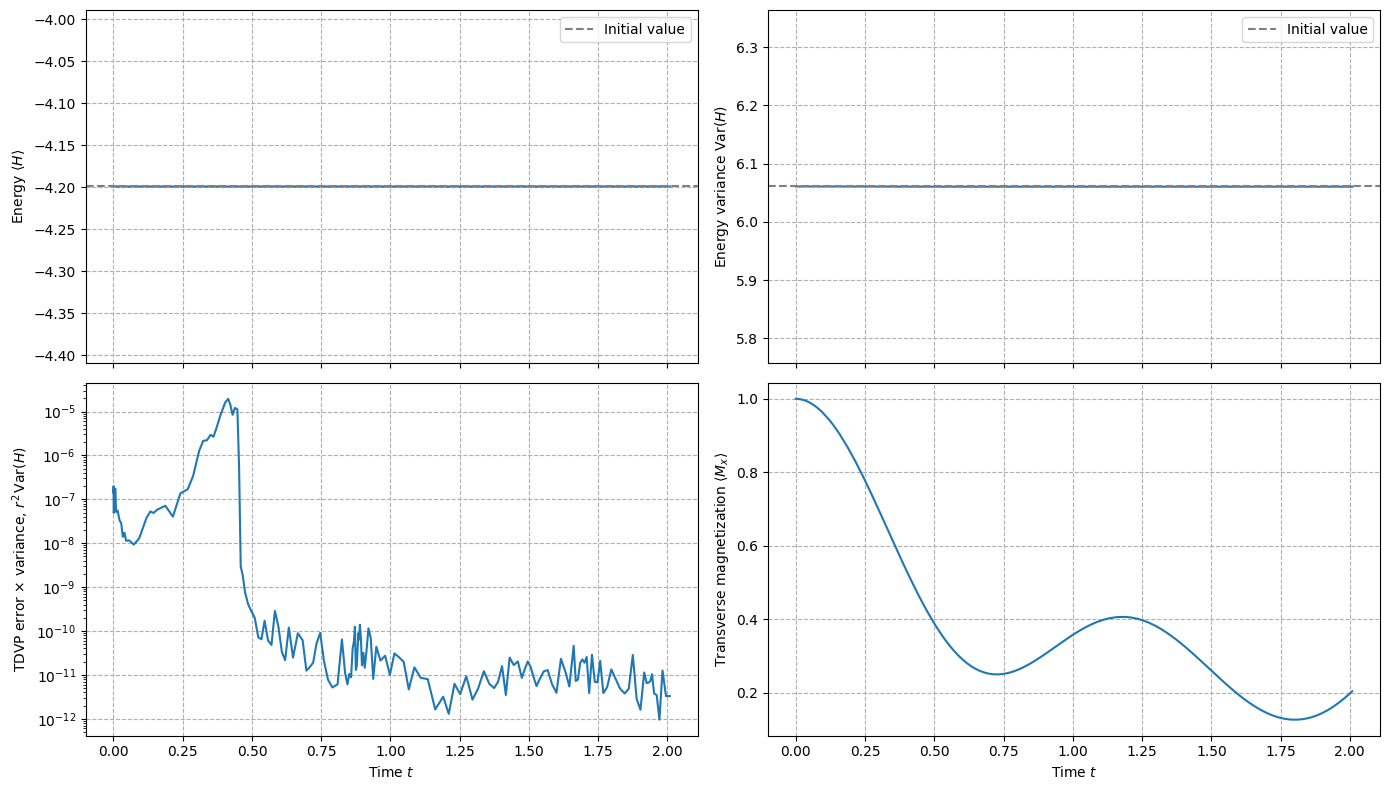

In [29]:
time = np.array(out["times"])
energy_mean = np.array(out["energy"]["mean"]).real
energy_var = np.array(out["energy"]["variance"]).real
magnetization = np.array(out["X"]["mean"]).real
tdvp_error = np.array(meta["tdvp_error"])

# Plot window of +-5% around the initial value: a conserved quantity looks flat
def set_relative_ylim(ax, value, rel=0.05):
    ax.set_ylim(value - rel * abs(value), value + rel * abs(value))

fig, axs = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

ax = axs[0, 0]
ax.plot(time, energy_mean)
ax.axhline(energy_mean[0], ls="--", color="gray", label="Initial value")
set_relative_ylim(ax, energy_mean[0])
ax.set_ylabel(r"Energy $\langle H\rangle$")
ax.legend()

ax = axs[0, 1]
ax.plot(time, energy_var)
ax.axhline(energy_var[0], ls="--", color="gray", label="Initial value")
set_relative_ylim(ax, energy_var[0])
ax.set_ylabel(r"Energy variance $\mathrm{Var}(H)$")
ax.legend()

ax = axs[1, 0]
ax.plot(time, tdvp_error * energy_var)
ax.set_yscale("log")
ax.set_ylabel(r"TDVP error $\times$ variance, $r^2\,\mathrm{Var}(H)$")

ax = axs[1, 1]
ax.plot(time, magnetization)
ax.set_ylabel(r"Transverse magnetization $\langle M_x\rangle$")

for ax in axs.flat:
    ax.grid(ls="--")
for ax in axs[1]:
    ax.set_xlabel(r"Time $t$")

plt.tight_layout()